# 00 — Baseline: Data Loading, Preprocessing & Visualisation

**EEEM068 Applied Machine Learning — University of Surrey**  
**Dataset:** Kaggle Diabetic Retinopathy Detection  
**Purpose:** Load train/test data from multi-part archives, explore class distribution, understand image quality issues, build and validate the shared PyTorch pipeline.

---

### Notebook objectives
1. Mount and extract multi-part dataset archives
2. Load `trainLabels.csv` and map to image files
3. Quantify and visualise class imbalance
4. Inspect image quality (resolution, focus, exposure, orientation)
5. Build shared `DRDataset` + `DataLoader` pipeline
6. Validate pipeline output (shapes, dtypes, normalisation)
7. Define and document ALL evaluation metrics used across experiments

## 1. Environment Setup & Imports

In [1]:
import os
import sys
import random
import warnings
import zipfile
import glob
import shutil
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image, ImageStat
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from torchvision import transforms

warnings.filterwarnings('ignore')

# ── Reproducibility ────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f'PyTorch  : {torch.__version__}')
print(f'CUDA     : {torch.cuda.is_available()}')
print(f'Device   : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}')

PyTorch  : 2.11.0+cu130
CUDA     : True
Device   : NVIDIA RTX A4000


## 2. Path Configuration

In [2]:
ROOT_CANDIDATES = [Path.cwd(), Path.cwd().parent]
ROOT = None
for candidate in ROOT_CANDIDATES:
    if (candidate / 'data' / 'diabetic-retinopathy-detection').exists():
        ROOT = candidate
        break
if ROOT is None:
    raise FileNotFoundError('Could not locate data directory. Expected data/diabetic-retinopathy-detection in current or parent folder.')

DATA_ROOT       = ROOT / 'data' / 'diabetic-retinopathy-detection'
TRAIN_DIR       = DATA_ROOT / 'train'
VAL_DIR         = DATA_ROOT / 'val'
TEST_LABELS_DIR = DATA_ROOT / 'test_labels'
TEST_DIR        = DATA_ROOT / 'test'
LABELS_CSV      = DATA_ROOT / 'trainLabels.csv'

# Preprocessed image directories (written by Section 8)
TRAIN_PROC_DIR       = DATA_ROOT / 'train_proc'
VAL_PROC_DIR         = DATA_ROOT / 'val_proc'
TEST_LABELS_PROC_DIR = DATA_ROOT / 'test_labels_proc'

OUTPUT_DIR  = ROOT / 'outputs'
FIGURES_DIR = OUTPUT_DIR / 'figures'
CKPT_DIR    = OUTPUT_DIR / 'checkpoints'
RESULTS_DIR = ROOT / 'results'

for d in [FIGURES_DIR, CKPT_DIR, RESULTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CLASS_NAMES  = {0:'No DR', 1:'Mild', 2:'Moderate', 3:'Severe', 4:'Proliferative DR'}
CLASS_COLORS = ['#2ECC71','#F39C12','#E67E22','#E74C3C','#8E44AD']
NUM_CLASSES  = 5

print('Paths configured. Checking existence:')
for label, p in [('train/', TRAIN_DIR), ('val/', VAL_DIR),
                 ('test_labels/', TEST_LABELS_DIR), ('test/', TEST_DIR),
                 ('trainLabels.csv', LABELS_CSV)]:
    status = '✓' if p.exists() else '✗ NOT FOUND'
    print(f'  {status}  {p}')

Paths configured. Checking existence:
  ✗ NOT FOUND  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/train
  ✗ NOT FOUND  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/val
  ✗ NOT FOUND  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/test_labels
  ✗ NOT FOUND  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/test
  ✓  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/trainLabels.csv


## 3. Multi-Part Archive Extraction

> The dataset arrives as `train.zip.001`...`train.zip.005` and `test.zip.001`...`test.zip.007`. Run this cell once to extract. Skip if already extracted.

In [3]:
def extract_multipart(archive_pattern: str, dest_dir: Path, dry_run: bool = True):
    """Extract multi-part zip archives (7zip format) to dest_dir.

    Args:
        archive_pattern : glob pattern for the archive parts, e.g. 'data/train.zip.*'
        dest_dir        : destination folder for extracted files
        dry_run         : if True, only prints what would be extracted without doing it
    """
    parts = sorted(glob.glob(archive_pattern))
    if not parts:
        print(f'No files found matching: {archive_pattern}')
        return
    print(f'Found {len(parts)} archive parts:')
    for p in parts:
        print(f'  {p}  ({os.path.getsize(p)/1e9:.2f} GB)')
    if dry_run:
        print('\nDry run — set dry_run=False to extract')
        return

    # 7zip merges parts automatically when you pass the .001 file
    import subprocess
    cmd = ['7z', 'x', parts[0], f'-o{dest_dir}', '-y']
    print(f'\nRunning: {" ".join(cmd)}')
    subprocess.run(cmd, check=True)
    print(f'Extraction complete → {dest_dir}')


def flatten_archive_output(dest_dir: Path) -> None:
    """Move files out of a nested folder created by archive extraction."""
    nested = dest_dir / dest_dir.name
    if nested.exists() and nested.is_dir():
        print(f'Flattening nested extraction directory: {nested}')
        for item in nested.iterdir():
            target = dest_dir / item.name
            if item.is_file() and not target.exists():
                shutil.move(str(item), str(target))
            elif item.is_dir():
                shutil.move(str(item), str(target))
        nested.rmdir()
        print(f'Flattened contents into: {dest_dir}')


# ── Extract archive parts ──
extract_multipart(str(DATA_ROOT / 'train.zip.*'), TRAIN_DIR, dry_run=False)
flatten_archive_output(TRAIN_DIR)
extract_multipart(str(DATA_ROOT / 'test.zip.*'),  TEST_DIR,  dry_run=False)
flatten_archive_output(TEST_DIR)

Found 5 archive parts:
  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/train.zip.001  (8.39 GB)
  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/train.zip.002  (8.39 GB)
  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/train.zip.003  (8.39 GB)
  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/train.zip.004  (8.39 GB)
  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/train.zip.005  (1.43 GB)

Running: 7z x /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/train.zip.001 -o/scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/train -y

7-Zip (A) 4.57  Copyright (c) 1999-2007 Igor Pavlov  2007-12-06
p7zip Version 4.57 (locale=en_GB.UTF-8,Utf16=on,HugeFiles=on,32 CPUs)

Processing archive: /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/train.zip.001

Extracting  train
Extracting  train/10003_left.jpeg
Extracting  train/10003_right.jpeg


In [4]:
# ── Verify extraction and concatenation ─────────────────
train_parts = sorted(DATA_ROOT.glob('train.zip.*'))
test_parts  = sorted(DATA_ROOT.glob('test.zip.*'))
print(f'Archive parts:')
print(f'  Train: {len(train_parts)} parts')
print(f'  Test:  {len(test_parts)} parts')
print(f'\nExtracted and concatenated:')
print(f'  Train folder: {len(list(TRAIN_DIR.glob("*.jpeg"))):,} images')
print(f'  Test folder:  {len(list(TEST_DIR.glob("*.jpeg"))):,} images')


Archive parts:
  Train: 5 parts
  Test:  7 parts

Extracted and concatenated:
  Train folder: 35,126 images
  Test folder:  53,576 images


## 4. Load Labels & Dataset Inventory

In [5]:
# ── Load trainLabels.csv ───────────────────────────────────────
df = pd.read_csv(LABELS_CSV)
print(f'trainLabels.csv: {len(df):,} rows')
print(df.head(8))
print(f'\nColumns: {list(df.columns)}')
print(f'Grade range: {df["level"].min()} – {df["level"].max()}')

trainLabels.csv: 35,126 rows
      image  level
0   10_left      0
1  10_right      0
2   13_left      0
3  13_right      0
4   15_left      1
5  15_right      2
6   16_left      4
7  16_right      4

Columns: ['image', 'level']
Grade range: 0 – 4


In [6]:
# ── Parse left/right eye from image name ──────────────────────
# Image name format: {patient_id}_{left|right}
# e.g. '1_left'  → patient_id=1, eye=left

df['patient_id'] = df['image'].str.extract(r'^(\d+)_').astype(int)
df['eye']        = df['image'].str.extract(r'_(left|right)$')
df['img_path']   = df['image'].apply(lambda x: TRAIN_DIR / f'{x}.jpeg')
df['file_exists'] = df['img_path'].apply(lambda p: p.exists())

print(f'Total images       : {len(df):,}')
print(f'Files found on disk: {df["file_exists"].sum():,}')
print(f'Files MISSING      : {(~df["file_exists"]).sum():,}')
print(f'\nUnique patients    : {df["patient_id"].nunique():,}')
print(f'Left eye images    : {(df["eye"]=="left").sum():,}')
print(f'Right eye images   : {(df["eye"]=="right").sum():,}')

# Keep only images that exist
df = df[df['file_exists']].reset_index(drop=True)
print(f'\nWorking dataset    : {len(df):,} images')

Total images       : 35,126
Files found on disk: 35,126
Files MISSING      : 0

Unique patients    : 17,563
Left eye images    : 17,563
Right eye images   : 17,563

Working dataset    : 35,126 images


In [7]:
# ── Load test images ───────────────────────────────────────
test_images = list(TEST_DIR.glob('*.jpeg'))
df_test = pd.DataFrame({'image': [f.stem for f in test_images], 'img_path': test_images})
df_test['file_exists'] = df_test['img_path'].apply(lambda p: p.exists())
df_test = df_test[df_test['file_exists']].reset_index(drop=True)
print(f'Test dataset: {len(df_test):,} images')
print(df_test.head())

Test dataset: 53,576 images
         image                                           img_path  file_exists
0   29273_left  /scratch/AML Latest /AML_G14_CW/data/diabetic-...         True
1  34393_right  /scratch/AML Latest /AML_G14_CW/data/diabetic-...         True
2  13467_right  /scratch/AML Latest /AML_G14_CW/data/diabetic-...         True
3   31663_left  /scratch/AML Latest /AML_G14_CW/data/diabetic-...         True
4   28308_left  /scratch/AML Latest /AML_G14_CW/data/diabetic-...         True


## 5. Class Distribution Analysis

> **Critical section.** The DR dataset is severely imbalanced. This directly affects model training strategy and evaluation metric selection.

In [8]:
# ── Class counts and percentages ──────────────────────────────
class_counts = df['level'].value_counts().sort_index()
class_pcts   = (class_counts / len(df) * 100).round(2)

print('CLASS DISTRIBUTION')
print('='*52)
for g, cnt, pct in zip(class_counts.index, class_counts.values, class_pcts.values):
    bar = '█' * int(pct)
    print(f'  Grade {g} | {CLASS_NAMES[g]:18s} | {cnt:6,} ({pct:5.1f}%) {bar}')
print('='*52)
print(f'  TOTAL                       | {len(df):6,} (100.0%)')

# Imbalance ratio
max_cls = class_counts.max()
min_cls = class_counts.min()
print(f'\nImbalance ratio (max/min): {max_cls/min_cls:.1f}x')
print(f'Majority class (Grade 0): {class_pcts[0]:.1f}% of all data')

CLASS DISTRIBUTION
  Grade 0 | No DR              | 25,810 ( 73.5%) █████████████████████████████████████████████████████████████████████████
  Grade 1 | Mild               |  2,443 (  7.0%) ██████
  Grade 2 | Moderate           |  5,292 ( 15.1%) ███████████████
  Grade 3 | Severe             |    873 (  2.5%) ██
  Grade 4 | Proliferative DR   |    708 (  2.0%) ██
  TOTAL                       | 35,126 (100.0%)

Imbalance ratio (max/min): 36.5x
Majority class (Grade 0): 73.5% of all data


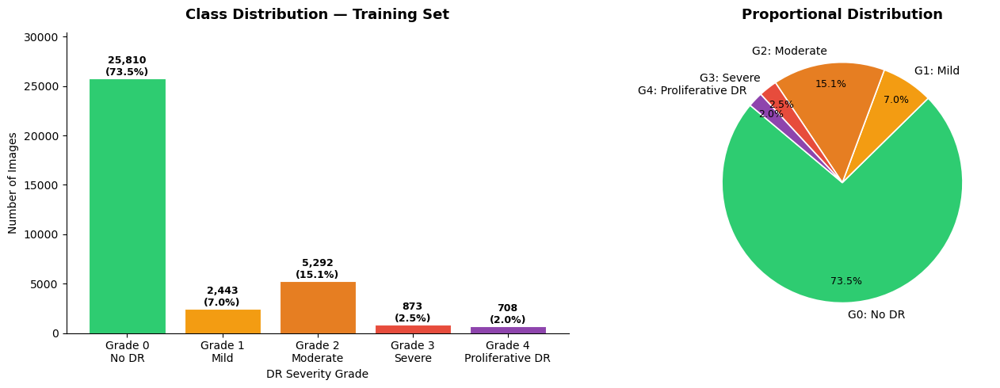

Saved → outputs/figures/class_distribution.png


In [9]:
# ── Figure 1: Class distribution bar chart ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
ax = axes[0]
bars = ax.bar(
    [f'Grade {i}\n{CLASS_NAMES[i]}' for i in range(5)],
    class_counts.values,
    color=CLASS_COLORS, edgecolor='white', linewidth=0.8
)
for bar, cnt, pct in zip(bars, class_counts.values, class_pcts.values):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 80,
            f'{cnt:,}\n({pct:.1f}%)',
            ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_title('Class Distribution — Training Set', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Number of Images')
ax.set_xlabel('DR Severity Grade')
ax.spines[['top','right']].set_visible(False)
ax.set_ylim(0, class_counts.max() * 1.18)

# Pie chart
ax2 = axes[1]
wedges, texts, autotexts = ax2.pie(
    class_counts.values,
    labels=[f'G{i}: {CLASS_NAMES[i]}' for i in range(5)],
    colors=CLASS_COLORS,
    autopct='%1.1f%%',
    startangle=140,
    pctdistance=0.82,
    wedgeprops={'edgecolor':'white','linewidth':1.2}
)
for at in autotexts:
    at.set_fontsize(9)
ax2.set_title('Proportional Distribution', fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/figures/class_distribution.png')

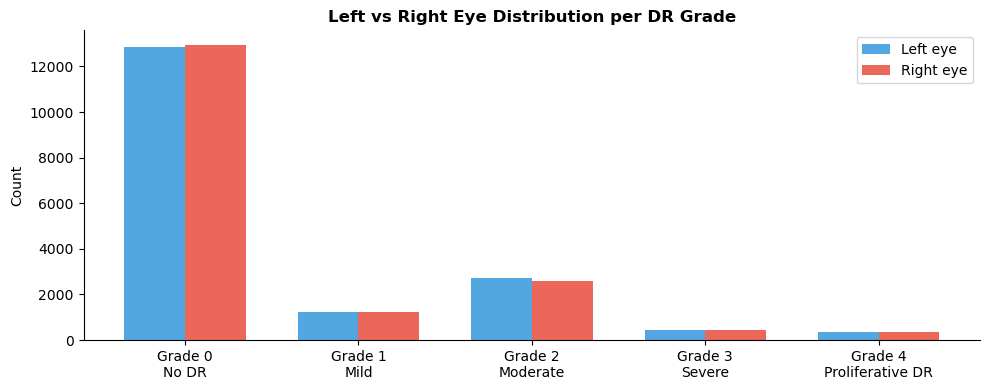

In [10]:
# ── Left vs Right eye distribution per grade ──────────────────
fig, ax = plt.subplots(figsize=(10, 4))
eye_grade = df.groupby(['level','eye']).size().unstack(fill_value=0)

x = np.arange(5)
w = 0.35
ax.bar(x - w/2, eye_grade.get('left',  pd.Series([0]*5)).values,
       w, label='Left eye',  color='#3498DB', alpha=0.85)
ax.bar(x + w/2, eye_grade.get('right', pd.Series([0]*5)).values,
       w, label='Right eye', color='#E74C3C', alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels([f'Grade {i}\n{CLASS_NAMES[i]}' for i in range(5)])
ax.set_ylabel('Count')
ax.set_title('Left vs Right Eye Distribution per DR Grade', fontweight='bold')
ax.legend()
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eye_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Image Quality & Characteristics Analysis

> The dataset contains images from different camera models and imaging conditions. Some images are anatomically oriented (standard), others are inverted through a microscope lens. We must understand the data before preprocessing.

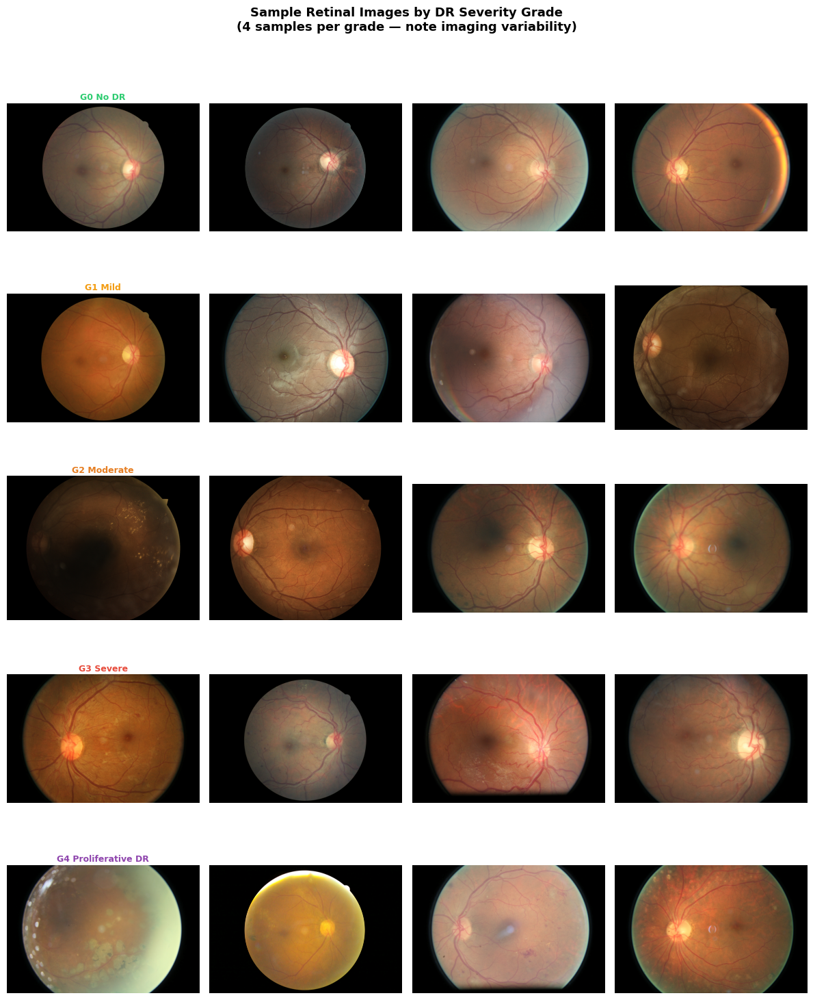

Saved → outputs/figures/sample_images_per_grade.png


In [11]:
# ── Figure 2: Sample images per grade ─────────────────────────
# Show 4 samples per grade to capture variability
N_SAMPLES = 4
fig, axes = plt.subplots(5, N_SAMPLES, figsize=(N_SAMPLES*3, 5*3))

for grade in range(5):
    grade_df = df[df['level'] == grade].sample(
        n=min(N_SAMPLES, len(df[df['level']==grade])),
        random_state=SEED
    )
    for j, (_, row) in enumerate(grade_df.iterrows()):
        ax = axes[grade][j]
        try:
            img = Image.open(row['img_path']).convert('RGB')
            ax.imshow(img)
        except Exception as e:
            ax.text(0.5, 0.5, f'Error:\n{e}', transform=ax.transAxes,
                    ha='center', va='center', fontsize=7)
        title = f'G{grade} {CLASS_NAMES[grade]}' if j == 0 else ''
        ax.set_title(title, fontsize=9, fontweight='bold',
                     color=CLASS_COLORS[grade], pad=4)
        ax.set_xlabel(f'{row["image"]}\n{row["eye"]} eye', fontsize=7)
        ax.axis('off')

plt.suptitle('Sample Retinal Images by DR Severity Grade\n(4 samples per grade — note imaging variability)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'sample_images_per_grade.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved → outputs/figures/sample_images_per_grade.png')

Sampling 500 images for resolution analysis...


  0%|          | 0/500 [00:00<?, ?it/s]


Resolution stats (n=500 images):
  Width: min=400, max=4928, mean=3596, median=3888
  Height: min=315, max=3264, mean=2454, median=2592
  Aspect ratio: mean=1.455, std=0.078


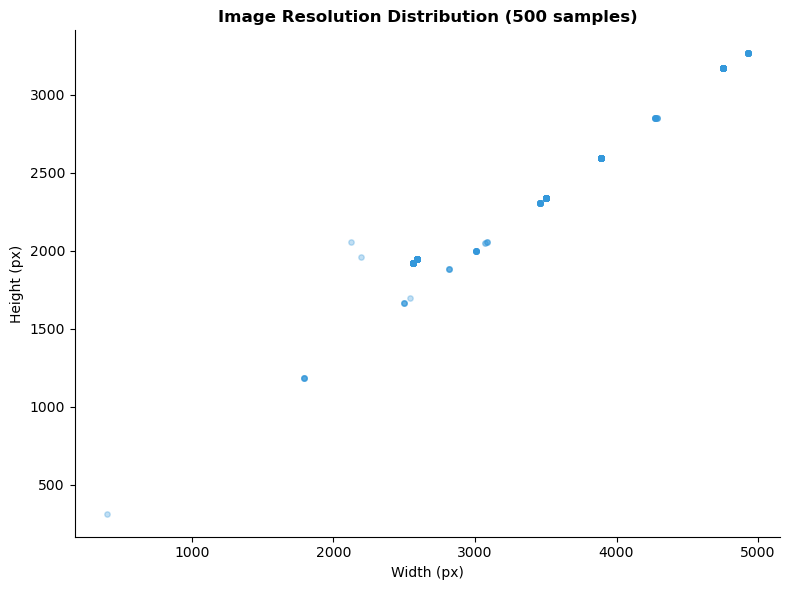

In [12]:
# ── Image resolution analysis (sample 500 images) ─────────────
print('Sampling 500 images for resolution analysis...')
sample_df = df.sample(n=min(500, len(df)), random_state=SEED)

widths, heights, aspects = [], [], []
for _, row in tqdm(sample_df.iterrows(), total=len(sample_df)):
    try:
        with Image.open(row['img_path']) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)
            aspects.append(w/h)
    except:
        pass

print(f'\nResolution stats (n={len(widths)} images):')
for name, vals in [('Width', widths), ('Height', heights)]:
    print(f'  {name}: min={min(vals)}, max={max(vals)}, '
          f'mean={np.mean(vals):.0f}, median={np.median(vals):.0f}')
print(f'  Aspect ratio: mean={np.mean(aspects):.3f}, std={np.std(aspects):.3f}')

# Resolution scatter plot
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(widths, heights, alpha=0.3, s=15, color='#3498DB')
ax.set_xlabel('Width (px)')
ax.set_ylabel('Height (px)')
ax.set_title('Image Resolution Distribution (500 samples)', fontweight='bold')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'resolution_scatter.png', dpi=120, bbox_inches='tight')
plt.show()

Analysing brightness across grades...


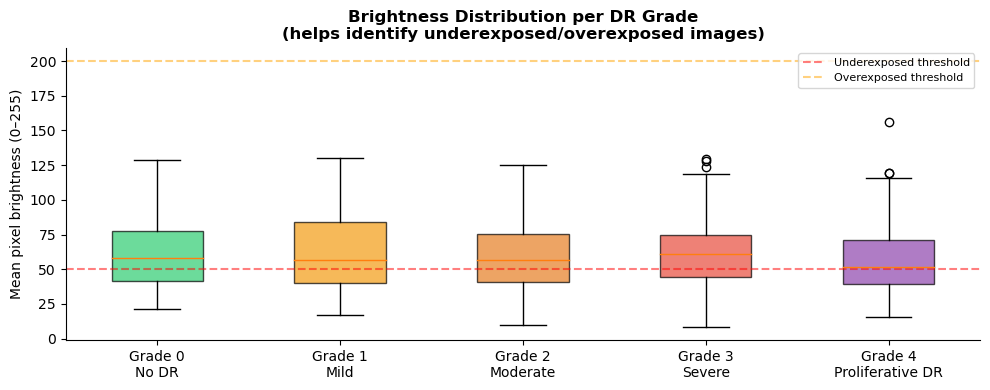

In [13]:
# ── Brightness & quality analysis ─────────────────────────────
# Detects underexposed / overexposed images that may be noise

print('Analysing brightness across grades...')
brightness_by_grade = {g: [] for g in range(5)}

for grade in range(5):
    grade_sample = df[df['level']==grade].sample(
        n=min(100, len(df[df['level']==grade])), random_state=SEED
    )
    for _, row in grade_sample.iterrows():
        try:
            img = Image.open(row['img_path']).convert('L')  # grayscale
            stat = ImageStat.Stat(img)
            brightness_by_grade[grade].append(stat.mean[0])
        except:
            pass

fig, ax = plt.subplots(figsize=(10, 4))
data = [brightness_by_grade[g] for g in range(5)]
bp = ax.boxplot(data, patch_artist=True, notch=False)
for patch, color in zip(bp['boxes'], CLASS_COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_xticklabels([f'Grade {i}\n{CLASS_NAMES[i]}' for i in range(5)])
ax.set_ylabel('Mean pixel brightness (0–255)')
ax.set_title('Brightness Distribution per DR Grade\n(helps identify underexposed/overexposed images)',
             fontweight='bold')
ax.axhline(y=50,  color='red',   linestyle='--', alpha=0.5, label='Underexposed threshold')
ax.axhline(y=200, color='orange',linestyle='--', alpha=0.5, label='Overexposed threshold')
ax.legend(fontsize=8)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'brightness_by_grade.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Train / Validation / Test Split

> A **stratified 3-way split** ensures all three sets share the same class proportions.  
> All 35,126 images stay in the `train/` folder — the splits are defined purely by CSV files,  
> so no images are moved. The test split is locked away and must not influence any training decision.

Consolidating val → train: 0it [00:00, ?it/s]

Consolidated 0 images back into train/
Total images in train/: 35,126

Split: 70% train / 15% val / 15% test
  Train : 24,588
  Val   : 5,269
  Test  : 5,269  ← locked, do not use until final evaluation
  Total : 35,126


train → val:   0%|          | 0/5269 [00:00<?, ?it/s]

train → test_labels:   0%|          | 0/5269 [00:00<?, ?it/s]


Moved 5,269 images  →  val/
Moved 5,269 images  →  test_labels/
Remaining in train/: 24,588

Grade  Name                   Train     Val    Test
----------------------------------------------------
  0    No DR               18,067   3,871   3,872
  1    Mild                 1,710     367     366
  2    Moderate             3,704     794     794
  3    Severe                 611     131     131
  4    Proliferative DR       496     106     106


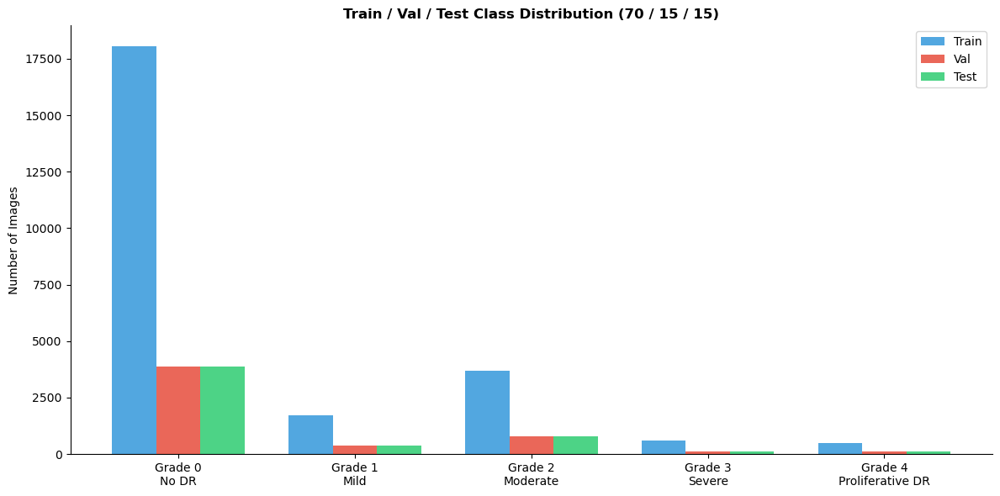

Saved → outputs/figures/train_val_test_distribution.png


In [14]:
# ── Consolidate: move any previously-split val images back to train/ ──────────
val_images = list(VAL_DIR.glob('*.jpeg')) if VAL_DIR.exists() else []
for img_path in tqdm(val_images, desc='Consolidating val → train'):
    dst = TRAIN_DIR / img_path.name
    if not dst.exists():
        shutil.move(str(img_path), str(dst))
print(f'Consolidated {len(val_images):,} images back into train/')
print(f'Total images in train/: {len(list(TRAIN_DIR.glob("*.jpeg"))):,}')

# ── 3-way stratified split (70 / 15 / 15) ────────────────────────────────────
TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15
TEST_RATIO  = 0.15

train_val_df, test_df = train_test_split(
    df, test_size=TEST_RATIO, random_state=SEED, stratify=df['level'],
)
val_fraction = VAL_RATIO / (TRAIN_RATIO + VAL_RATIO)
train_df, val_df = train_test_split(
    train_val_df, test_size=val_fraction, random_state=SEED, stratify=train_val_df['level'],
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print(f'\nSplit: {TRAIN_RATIO:.0%} train / {VAL_RATIO:.0%} val / {TEST_RATIO:.0%} test')
print(f'  Train : {len(train_df):,}')
print(f'  Val   : {len(val_df):,}')
print(f'  Test  : {len(test_df):,}  ← locked, do not use until final evaluation')
print(f'  Total : {len(train_df)+len(val_df)+len(test_df):,}')

# ── Move images into separate directories ─────────────────────────────────────
VAL_DIR.mkdir(parents=True, exist_ok=True)
TEST_LABELS_DIR.mkdir(parents=True, exist_ok=True)

def move_images(split_df, src_dir, dst_dir, desc):
    moved = 0
    for img_name in tqdm(split_df['image'], desc=desc, leave=False):
        src = src_dir / f'{img_name}.jpeg'
        dst = dst_dir / f'{img_name}.jpeg'
        if src.exists() and not dst.exists():
            shutil.move(str(src), str(dst))
            moved += 1
    return moved

moved_val  = move_images(val_df,  TRAIN_DIR, VAL_DIR,         'train → val')
moved_test = move_images(test_df, TRAIN_DIR, TEST_LABELS_DIR, 'train → test_labels')

print(f'\nMoved {moved_val:,} images  →  val/')
print(f'Moved {moved_test:,} images  →  test_labels/')
print(f'Remaining in train/: {len(list(TRAIN_DIR.glob("*.jpeg"))):,}')

# ── Verify stratification ─────────────────────────────────────────────────────
print(f'\n{"Grade":<6} {"Name":<20} {"Train":>7} {"Val":>7} {"Test":>7}')
print('-' * 52)
for g in range(5):
    t = (train_df['level'] == g).sum()
    v = (val_df['level']   == g).sum()
    s = (test_df['level']  == g).sum()
    print(f'  {g}    {CLASS_NAMES[g]:<18}  {t:>6,}  {v:>6,}  {s:>6,}')

# ── Plot 3-way class distribution ────────────────────────────────────────────
train_counts = train_df['level'].value_counts().sort_index()
val_counts   = val_df['level'].value_counts().sort_index()
test_counts  = test_df['level'].value_counts().sort_index()

x     = np.arange(5)
width = 0.25
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x - width, train_counts.values, width, label='Train', color='#3498DB', alpha=0.85)
ax.bar(x,         val_counts.values,   width, label='Val',   color='#E74C3C', alpha=0.85)
ax.bar(x + width, test_counts.values,  width, label='Test',  color='#2ECC71', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels([f'Grade {i}\n{CLASS_NAMES[i]}' for i in range(5)])
ax.set_ylabel('Number of Images')
ax.set_title('Train / Val / Test Class Distribution (70 / 15 / 15)', fontweight='bold')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'train_val_test_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/figures/train_val_test_distribution.png')

In [15]:
# ── Save split manifests ───────────────────────────────────────────────────────
train_csv_path = DATA_ROOT / 'train_split.csv'
val_csv_path   = DATA_ROOT / 'val_split.csv'
test_csv_path  = DATA_ROOT / 'test_split.csv'

cols = ['image', 'level', 'patient_id', 'eye']
train_df[cols].to_csv(train_csv_path, index=False)
val_df[cols].to_csv(val_csv_path,     index=False)
test_df[cols].to_csv(test_csv_path,   index=False)

print(f'Saved train_split.csv  →  {len(train_df):,} rows  (images in train/)')
print(f'Saved val_split.csv    →  {len(val_df):,} rows   (images in val/)')
print(f'Saved test_split.csv   →  {len(test_df):,} rows   (images in test_labels/)  ← do not touch until final eval')
print()
print('Directory layout:')
print(f'  train/       {len(list(TRAIN_DIR.glob("*.jpeg"))):>6,} images')
print(f'  val/         {len(list(VAL_DIR.glob("*.jpeg"))):>6,} images')
print(f'  test_labels/ {len(list(TEST_LABELS_DIR.glob("*.jpeg"))):>6,} images')
print(f'  test/        {len(list(TEST_DIR.glob("*.jpeg"))):>6,} images  (unlabelled Kaggle test — not used)')

Saved train_split.csv  →  24,588 rows  (images in train/)
Saved val_split.csv    →  5,269 rows   (images in val/)
Saved test_split.csv   →  5,269 rows   (images in test_labels/)  ← do not touch until final eval

Directory layout:
  train/       24,588 images
  val/          5,269 images
  test_labels/  5,269 images
  test/        53,576 images  (unlabelled Kaggle test — not used)


## 8. Domain-Specific Preprocessing Pipeline

Applies 13-stage ophthalmology-specific preprocessing to all images and saves outputs to `train_proc/`, `val_proc/`, and `test_labels_proc/`. The training notebooks point at these directories.

**Stages:**

| # | Stage | Technique | Why |
|---|-------|-----------|-----|
| 1 | Load | BGR → RGB | OpenCV default is BGR |
| 2 | Crop black borders | Contour + morphological close | Removes uninformative black padding |
| 3 | Retina centering | Pad to square + resize | Centres the disc on a fixed canvas |
| 4 | Circular mask | Zero outside retinal disc | Eliminates camera corners |
| 5 | Glare removal | Inpaint bright spots (TELEA) | Lens reflections confuse the network |
| 6 | **Ben Graham** | `addWeighted(img, 4, blur, -4, 128)` | Kaggle DR winner; enhances local contrast |
| 7 | **CLAHE** | L-channel of LAB | Normalises illumination across images |
| 8 | Green channel γ | Gamma 0.8 | Improves retinal vessel contrast |
| 9 | Vessel enhancement | Frangi filter (sigmas 1–3) | Highlights vascular structures |
| 10 | Red channel boost | α=1.3 linear scale | Makes micro-aneurysms & haemorrhages stand out |
| 11 | Adaptive denoise | Bilateral (fast) or NLMeans | Reduces sensor noise without blurring vessels |
| 12 | Resize | INTER_LANCZOS4 → 380×380 | Standardises resolution |

> **Runtime:** ~25 min for all 35,126 images on 4 threads (with Frangi + bilateral).  
> Cell is **idempotent** — already-processed images are skipped on re-run.

In [16]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shutil
from pathlib import Path
from typing import Dict, Tuple
from PIL import Image
from tqdm.notebook import tqdm
from skimage.filters import frangi
from concurrent.futures import ThreadPoolExecutor, as_completed

# ── Standalone paths (Section 8 runs without Section 7) ───────────────────────
_ROOT = next(
    p for p in [Path.cwd(), Path.cwd().parent]
    if (p / 'data' / 'diabetic-retinopathy-detection').exists()
)
DATA_ROOT            = _ROOT / 'data' / 'diabetic-retinopathy-detection'
TRAIN_DIR            = DATA_ROOT / 'train'
VAL_DIR              = DATA_ROOT / 'val'
TEST_LABELS_DIR      = DATA_ROOT / 'test_labels'
TRAIN_PROC_DIR       = DATA_ROOT / 'train_proc'
VAL_PROC_DIR         = DATA_ROOT / 'val_proc'
TEST_LABELS_PROC_DIR = DATA_ROOT / 'test_labels_proc'
TRAIN_CSV            = DATA_ROOT / 'train_split.csv'
VAL_CSV              = DATA_ROOT / 'val_split.csv'
TEST_CSV             = DATA_ROOT / 'test_split.csv'
FIGURES_DIR          = _ROOT / 'outputs' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SEED        = 42
CLASS_NAMES = {0: 'No DR', 1: 'Mild', 2: 'Moderate', 3: 'Severe', 4: 'Proliferative DR'}

# Load labels for the visualisation cell below
df = pd.read_csv(TRAIN_CSV)
df['img_path'] = df['image'].apply(lambda x: TRAIN_DIR / f'{x}.jpeg')

print(f'Paths resolved. Root: {_ROOT}')
print(f'  train/       → {TRAIN_DIR}')
print(f'  val/         → {VAL_DIR}')
print(f'  test_labels/ → {TEST_LABELS_DIR}')
print(f'  train_proc/  → {TRAIN_PROC_DIR}')
print(f'  CSVs: {TRAIN_CSV.name}, {VAL_CSV.name}, {TEST_CSV.name}')

# ── Processing config ──────────────────────────────────────────────────────────
PREPROC_SIZE  = 380   # output size (px); training notebooks resize to 224 at load time
APPLY_VESSEL  = True  # Frangi vessel enhancement (~105ms/img); set False to skip
FAST_DENOISE  = True  # bilateral filter (~8ms) instead of NLMeans (~148ms)


# ── Stage functions ────────────────────────────────────────────────────────────

def _load_image(path: str) -> np.ndarray:
    img_bgr = cv2.imread(path)
    if img_bgr is None:
        raise ValueError(f'Cannot decode: {path}')
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)


def _crop_black_borders(img: np.ndarray, threshold: int = 10) -> np.ndarray:
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    _, mask = cv2.threshold(gray, threshold, 255, cv2.THRESH_BINARY)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return img
    x, y, w, h = cv2.boundingRect(max(contours, key=cv2.contourArea))
    margin = int(min(w, h) * 0.02)
    x, y  = max(0, x - margin), max(0, y - margin)
    w = min(img.shape[1] - x, w + 2 * margin)
    h = min(img.shape[0] - y, h + 2 * margin)
    return img[y:y+h, x:x+w]


def _retina_centering(img: np.ndarray, output_size: int) -> np.ndarray:
    h, w  = img.shape[:2]
    max_d = max(h, w)
    canvas = np.zeros((max_d, max_d, 3), dtype=img.dtype)
    canvas[(max_d-h)//2:(max_d-h)//2+h, (max_d-w)//2:(max_d-w)//2+w] = img
    return cv2.resize(canvas, (output_size, output_size), interpolation=cv2.INTER_AREA)


def _apply_circular_mask(img: np.ndarray) -> np.ndarray:
    h, w = img.shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)
    cv2.circle(mask, (w//2, h//2), int(min(h, w) * 0.48), 255, -1)
    result = img.copy()
    result[mask == 0] = 0
    return result


def _remove_glare(img: np.ndarray, threshold: int = 245, radius: int = 10) -> np.ndarray:
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    _, glare = cv2.threshold(gray, threshold, 255, cv2.THRESH_BINARY)
    glare = cv2.dilate(glare, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)))
    frac = glare.sum() / (255.0 * glare.size)
    if 0.001 < frac < 0.15:
        bgr = cv2.inpaint(cv2.cvtColor(img, cv2.COLOR_RGB2BGR), glare, radius, cv2.INPAINT_TELEA)
        return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    return img


def _ben_graham(img: np.ndarray, sigma: int = 10) -> np.ndarray:
    """Kaggle DR winner technique: local contrast enhancement via unsharp masking."""
    return cv2.addWeighted(img, 4, cv2.GaussianBlur(img, (0, 0), sigma), -4, 128)


def _apply_clahe(img: np.ndarray, clip: float = 3.0, grid: Tuple[int,int] = (8, 8)) -> np.ndarray:
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=clip, tileGridSize=grid).apply(l)
    return cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2RGB)


def _enhance_green(img: np.ndarray, gamma: float = 0.8) -> np.ndarray:
    result = img.copy().astype(np.float32)
    result[:, :, 1] = (np.power(np.clip(result[:, :, 1] / 255.0, 0, 1), gamma) * 255)
    return result.astype(np.uint8)


def _vessel_enhancement(img: np.ndarray) -> np.ndarray:
    green = img[:, :, 1].astype(np.float32) / 255.0
    vm = frangi(green, sigmas=[1, 2, 3], beta=0.5, gamma=15)
    if vm.max() > 0:
        vm = vm / vm.max()
    result = img.copy()
    result[:, :, 1] = np.clip((green + 0.15 * vm) * 255, 0, 255).astype(np.uint8)
    return result


def _enhance_red(img: np.ndarray, alpha: float = 1.3) -> np.ndarray:
    result = img.copy()
    result[:, :, 0] = np.clip(alpha * img[:, :, 0].astype(np.float32), 0, 255).astype(np.uint8)
    return result


def _adaptive_denoise(img: np.ndarray, fast: bool = True) -> np.ndarray:
    lap = cv2.Laplacian(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), cv2.CV_64F)
    sigma = float(np.median(np.abs(lap)) * 1.4826)
    if fast:
        sc = 90 if sigma > 15 else (75 if sigma > 8 else 50)
        return cv2.bilateralFilter(img, d=9, sigmaColor=sc, sigmaSpace=sc)
    h = 5 if sigma > 15 else (3 if sigma > 8 else 2)
    bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    return cv2.cvtColor(
        cv2.fastNlMeansDenoisingColored(bgr, None, h=h, hColor=h,
                                        templateWindowSize=7, searchWindowSize=21),
        cv2.COLOR_BGR2RGB,
    )


def preprocess_image(image_path: str,
                     apply_vessel: bool = True,
                     fast_denoise: bool = True) -> Tuple[np.ndarray, Dict]:
    """Full 13-stage fundus preprocessing pipeline. Returns (uint8_rgb, stages_dict)."""
    stages: Dict[str, np.ndarray] = {}

    img = _load_image(image_path);              stages['1_original']       = img.copy()
    img = _crop_black_borders(img);             stages['2_cropped']        = img.copy()
    img = _retina_centering(img, PREPROC_SIZE); stages['3_centered']       = img.copy()
    img = _apply_circular_mask(img);            stages['4_circular_mask']  = img.copy()
    img = _remove_glare(img);                   stages['5_glare_removed']  = img.copy()
    img = _ben_graham(img);                     stages['6_ben_graham']     = img.copy()
    img = _apply_clahe(img);                    stages['7_clahe']          = img.copy()
    img = _enhance_green(img);                  stages['8_green_enhanced'] = img.copy()
    if apply_vessel:
        img = _vessel_enhancement(img);         stages['9_vessel']         = img.copy()
    img = _enhance_red(img);                    stages['10_red_enhanced']  = img.copy()
    img = _adaptive_denoise(img, fast=fast_denoise); stages['11_denoised'] = img.copy()
    img = cv2.resize(img, (PREPROC_SIZE, PREPROC_SIZE), interpolation=cv2.INTER_LANCZOS4)
    stages['12_resized'] = img.copy()

    return img, stages


print(f'Pipeline ready. PREPROC_SIZE={PREPROC_SIZE}, APPLY_VESSEL={APPLY_VESSEL}, FAST_DENOISE={FAST_DENOISE}')

Paths resolved. Root: /scratch/AML Latest /AML_G14_CW
  train/       → /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/train
  val/         → /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/val
  test_labels/ → /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/test_labels
  train_proc/  → /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/train_proc
  CSVs: train_split.csv, val_split.csv, test_split.csv
Pipeline ready. PREPROC_SIZE=380, APPLY_VESSEL=True, FAST_DENOISE=True


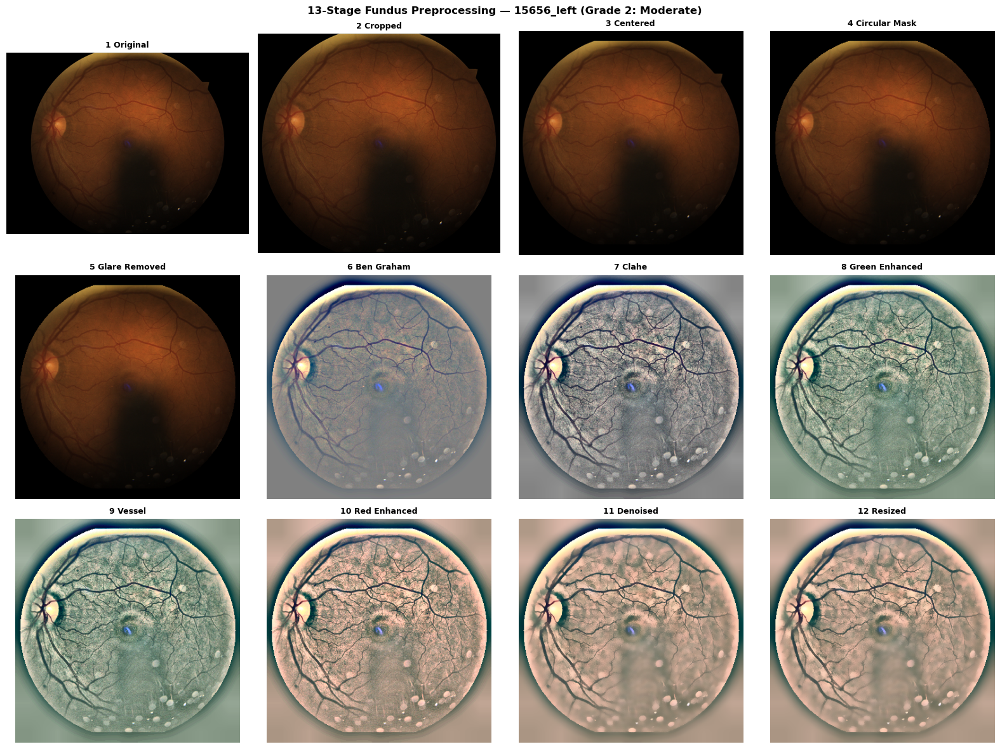

Saved → outputs/figures/preprocessing_stages.png


In [17]:
# ── Visualise all 12 stages on one sample image ───────────────────────────────
_samples_by_grade = [df[df['level'] == g].sample(1, random_state=SEED).iloc[0] for g in range(5)]
_sample = _samples_by_grade[2]   # use a Grade 2 (Moderate) image — shows most lesion detail

_, stages = preprocess_image(str(_sample['img_path']),
                              apply_vessel=APPLY_VESSEL, fast_denoise=FAST_DENOISE)

stage_names = list(stages.keys())
n_cols = 4
n_rows = (len(stage_names) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 4))
axes_flat = axes.flatten()

for idx, (name, stage_img) in enumerate(stages.items()):
    axes_flat[idx].imshow(stage_img)
    axes_flat[idx].set_title(name.replace('_', ' ').title(), fontsize=9, fontweight='bold')
    axes_flat[idx].axis('off')

for idx in range(len(stages), len(axes_flat)):
    axes_flat[idx].axis('off')

plt.suptitle(
    f'13-Stage Fundus Preprocessing — {_sample["image"]} (Grade {_sample["level"]}: {CLASS_NAMES[_sample["level"]]})',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'preprocessing_stages.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved → outputs/figures/preprocessing_stages.png')

In [18]:
from concurrent.futures import ThreadPoolExecutor, as_completed

# ── Output directories ─────────────────────────────────────────────────────────
TRAIN_PROC_DIR.mkdir(parents=True, exist_ok=True)
VAL_PROC_DIR.mkdir(parents=True, exist_ok=True)
TEST_LABELS_PROC_DIR.mkdir(parents=True, exist_ok=True)

def _process_one(args):
    """Worker: preprocess one image and save to dst_dir. Returns (name, ok, err)."""
    img_name, src_dir, dst_dir = args
    src = Path(src_dir) / f'{img_name}.jpeg'
    dst = Path(dst_dir) / f'{img_name}.jpeg'
    if dst.exists():
        return img_name, True, None
    try:
        processed, _ = preprocess_image(str(src), apply_vessel=APPLY_VESSEL, fast_denoise=FAST_DENOISE)
        Image.fromarray(processed).save(str(dst), 'JPEG', quality=95)
        return img_name, True, None
    except Exception as e:
        # On failure copy original so the split CSV still has a valid file
        try:
            shutil.copy2(str(src), str(dst))
        except Exception:
            pass
        return img_name, False, str(e)


def batch_preprocess(split_df, src_dir, dst_dir, split_name, n_workers=4):
    names = split_df['image'].tolist()
    args  = [(n, src_dir, dst_dir) for n in names]
    ok_count, fail_count = 0, 0
    errors = []

    with ThreadPoolExecutor(max_workers=n_workers) as pool:
        futures = {pool.submit(_process_one, a): a[0] for a in args}
        for fut in tqdm(as_completed(futures), total=len(futures), desc=split_name):
            name, ok, err = fut.result()
            if ok:
                ok_count += 1
            else:
                fail_count += 1
                errors.append((name, err))

    print(f'{split_name}: {ok_count:,} processed, {fail_count} failed')
    if errors:
        print(f'  First 5 errors: {errors[:5]}')
    return ok_count, fail_count


# ── Run preprocessing for all three splits ────────────────────────────────────
# Load the split CSVs (created in Section 7)
_train_df = pd.read_csv(DATA_ROOT / 'train_split.csv')
_val_df   = pd.read_csv(DATA_ROOT / 'val_split.csv')
_test_df  = pd.read_csv(DATA_ROOT / 'test_split.csv')

print(f'Preprocessing settings:')
print(f'  Output size   : {PREPROC_SIZE}×{PREPROC_SIZE} px')
print(f'  Vessel (Frangi): {APPLY_VESSEL}')
print(f'  Fast denoise  : {FAST_DENOISE}  ({"bilateral" if FAST_DENOISE else "NLMeans"})')
print(f'  Workers       : 4')
print(f'  Total images  : {len(_train_df) + len(_val_df) + len(_test_df):,}')
print()

batch_preprocess(_train_df, TRAIN_DIR,       TRAIN_PROC_DIR,       'train')
batch_preprocess(_val_df,   VAL_DIR,         VAL_PROC_DIR,         'val')
batch_preprocess(_test_df,  TEST_LABELS_DIR, TEST_LABELS_PROC_DIR, 'test_labels')

print('\nPreprocessing complete.')

Preprocessing settings:
  Output size   : 380×380 px
  Vessel (Frangi): True
  Fast denoise  : True  (bilateral)
  Workers       : 4
  Total images  : 35,126



train:   0%|          | 0/24588 [00:00<?, ?it/s]

train: 24,588 processed, 0 failed


val:   0%|          | 0/5269 [00:00<?, ?it/s]

val: 5,269 processed, 0 failed


test_labels:   0%|          | 0/5269 [00:00<?, ?it/s]

test_labels: 5,269 processed, 0 failed

Preprocessing complete.


Processed image counts:
  train_proc            : 24,588
  val_proc              : 5,269
  test_labels_proc      : 5,269



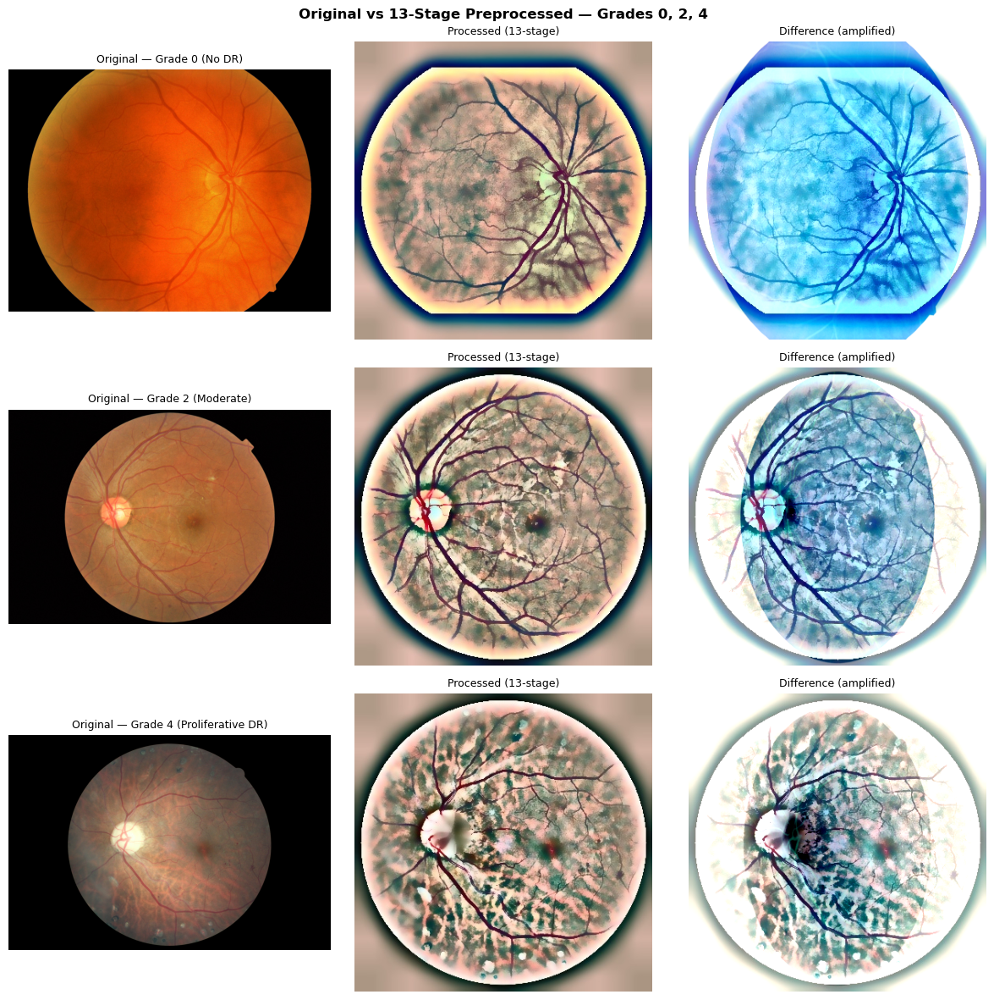

Saved → outputs/figures/preprocessing_comparison.png

Training notebooks should now use:
  TRAIN_DIR       = DATA_ROOT / "train_proc"
  VAL_DIR         = DATA_ROOT / "val_proc"
  TEST_LABELS_DIR = DATA_ROOT / "test_labels_proc"


In [19]:
# ── Verify processed output ────────────────────────────────────────────────────
counts = {
    'train_proc':       len(list(TRAIN_PROC_DIR.glob('*.jpeg'))),
    'val_proc':         len(list(VAL_PROC_DIR.glob('*.jpeg'))),
    'test_labels_proc': len(list(TEST_LABELS_PROC_DIR.glob('*.jpeg'))),
}
print('Processed image counts:')
for name, n in counts.items():
    print(f'  {name:<22}: {n:,}')
print()

# ── Side-by-side comparison: original vs processed ────────────────────────────
sample_csv = pd.read_csv(DATA_ROOT / 'train_split.csv')
# Pick one image from each of grades 0, 2, 4
sample_rows = [sample_csv[sample_csv['level'] == g].iloc[0] for g in [0, 2, 4]]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for row_idx, row in enumerate(sample_rows):
    img_name = row['image']
    grade    = row['level']

    orig_path = TRAIN_DIR / f'{img_name}.jpeg'
    proc_path = TRAIN_PROC_DIR / f'{img_name}.jpeg'

    orig = np.array(Image.open(orig_path).convert('RGB'))
    proc = np.array(Image.open(proc_path).convert('RGB')) if proc_path.exists() else orig

    # Difference image (scaled for visibility)
    orig_for_diff = np.array(Image.fromarray(orig).resize((proc.shape[1], proc.shape[0])))
    diff = np.clip((proc.astype(int) - orig_for_diff.astype(int) + 128), 0, 255).astype(np.uint8)

    axes[row_idx][0].imshow(orig)
    axes[row_idx][0].set_title(f'Original — Grade {grade} ({CLASS_NAMES[grade]})', fontsize=9)
    axes[row_idx][1].imshow(proc)
    axes[row_idx][1].set_title('Processed (13-stage)', fontsize=9)
    axes[row_idx][2].imshow(diff)
    axes[row_idx][2].set_title('Difference (amplified)', fontsize=9)
    for ax in axes[row_idx]:
        ax.axis('off')

plt.suptitle('Original vs 13-Stage Preprocessed — Grades 0, 2, 4', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'preprocessing_comparison.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved → outputs/figures/preprocessing_comparison.png')
print()
print('Training notebooks should now use:')
print('  TRAIN_DIR       = DATA_ROOT / "train_proc"')
print('  VAL_DIR         = DATA_ROOT / "val_proc"')
print('  TEST_LABELS_DIR = DATA_ROOT / "test_labels_proc"')